# Ansatz: is PINO's advantage the FNO or the grid residual?

PINO's single-instance solve (instance-wise fine-tuning) minimizes a PDE residual computed on a grid, with an FNO as the ansatz. A PINN minimizes the same equation with a coordinate MLP and autograd derivatives. Which ingredient matters?

Three methods solve the **same** Kolmogorov instance (Re = 500, T = 0.125, a state on the chaotic attractor) from the PDE loss alone, without data, from random initialization:

| Method | Ansatz | Derivatives |
|---|---|---|
| **FNO** | FNO (width 32, modes 8×8×8), input $w_0$ on the grid | Fourier in space, Crank–Nicolson in time, on the grid |
| **MLP + grid** | Fourier-feature MLP $(x, y, t) \mapsto w$ (16 frequencies, 4 × 128, tanh), evaluated on the grid | exactly the same grid residual |
| **PINN** | the same MLP with outputs $(w, \psi)$ | autograd at 4096 random collocation points per step, vorticity / stream-function form |

All three: 3000 Adam steps at lr 1e-3 with cosine decay, initial-condition weight 5, two instances, and PDE grids 16², 32² and 64² in space with 33 time points.

**The floor.** For each grid, the error of the **exact minimizer of the discrete grid loss** (L-BFGS directly on the grid values, initial frame fixed). A method that uses the grid residual and reaches the floor has no optimization deficit left; what remains is discretization error.

Reference: Li, Zheng et al., *Physics-Informed Neural Operator for Learning Partial Differential Equations*, arXiv:2111.03794. This notebook reads the saved results in `../results/ansatz`.

In [1]:
import os, sys, json
sys.path.insert(0, os.path.abspath(".."))          # repo root
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
import analysis as an, pino_bench as pb, experiments as ex
pd.set_option("display.width", 200)

### Reproducing
`python ansatz_experiment.py` runs all 18 solves (about 6 hours on 2 CPU cores, resumable) and writes to `../runs/ansatz_cn/`. Configuration:

In [2]:
import ansatz_experiment as ae
dict(Re=ae.RE, T=ae.T, time_points=ae.NT, grids=ae.GRIDS, instances=ae.SEEDS, ic_weight=ae.W_IC, time_scheme=ae.TIME_SCHEME, **ae.CFG)

{'Re': 500.0,
 'T': 0.125,
 'time_points': 33,
 'grids': [16, 32, 64],
 'instances': [1, 2],
 'ic_weight': 5.0,
 'time_scheme': 'cn',
 'steps': 3000,
 'lr': 0.001,
 'mlp_width': 128,
 'mlp_depth': 4,
 'n_freq': 16,
 'pinn_batch': 4096,
 'fno_width': 32,
 'fno_modes': (8, 8, 8)}

## Results
Error (%) against the 256² reference, per grid and instance, next to the floor.

In [3]:
t = an.ansatz_table(); t

method         floor    FNO  MLP + grid   PINN
grid instance                                 
16   1         44.35  44.35       43.04  47.56
     2         36.17  36.17       39.13  42.24
32   1         33.70  33.69       39.31  41.71
     2         23.77  23.77       39.58  41.88
64   1         15.37  11.35       39.43  42.27
     2         12.29   9.76       38.97  41.09

In [4]:
t.groupby('grid').mean().round(2)

method,floor,FNO,MLP + grid,PINN
grid,,,,
16,40.26,40.26,41.08,44.90
32,28.74,28.73,39.44,41.80
64,13.83,10.56,39.20,41.68


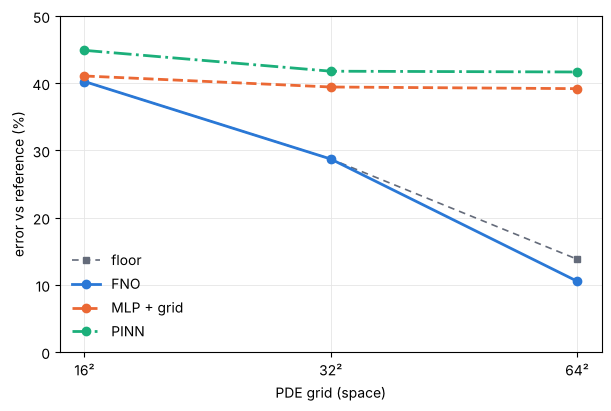

In [5]:
fig = an.plot_ansatz(); plt.show()

## Why Crank–Nicolson, not the paper's central differences

The paper's time derivative is a central difference on the interior frames, $(w_{n+1} - w_{n-1}) / 2\Delta t$ at $n = 1, \dots, N-1$. With the initial frame fixed, that is $N - 1$ equations for $N$ unknown frames: the loss has a **family of exact minimizers** (a leapfrog parasitic mode). Multi-start L-BFGS found minimizers with residual about $10^{-6}$ that lie up to 31% apart, so the "floor" of that loss is not defined.

Crank–Nicolson, $(w_{n+1} - w_n)/\Delta t + \tfrac12 (A(w_{n+1}) + A(w_n)) = 0$ for $n = 0, \dots, N-1$, is square, second order and has a unique minimizer. It is available in `pino_bench` as `cfg["time_scheme"] = "cn"`.

A first run used the central residual (saved in `../results/ansatz_central`, instance 1 complete). The results barely changed: the FNO's implicit bias already picked a smooth solution close to the Crank–Nicolson one.

In [6]:
old = {os.path.basename(f)[:-5]: 100 * json.load(open(f))["final_err"]
       for f in sorted(__import__("glob").glob(os.path.join(an.RESULTS, "ansatz_central", "*_n*_s1.json")))}
new = an.ansatz_table().xs(1, level="instance")
cmp = pd.DataFrame({f"{an.ANSATZ[m]} central": [old.get(f"{m}_n{n}_s1") for n in new.index] for m in an.ANSATZ}, index=new.index)
pd.concat([cmp, new.drop(columns="floor").add_suffix(" CN")], axis=1).round(2)

,FNO central,MLP + grid central,PINN central,FNO CN,MLP + grid CN,PINN CN
grid,,,,,,
16,44.35,43.30,47.56,44.35,43.04,47.56
32,33.71,39.24,41.71,33.69,39.31,41.71
64,11.21,39.31,42.27,11.35,39.43,42.27


## Observations

- **The FNO tracks the floor.** On 16² and 32² it matches the exact discrete minimizer to two decimals; on 64² it ends *below* it (10.6% against 13.8% on average). Its error falls with the grid exactly as the discretization allows.
- **The floor is not a lower bound.** An iterate that has not fully converged can lie closer to the reference than the exact minimizer, as the FNO does at 64².
- **The MLP with the same grid residual stalls near 40% on every grid**, and so does the PINN (about 42%). Their error does not improve with resolution: optimization, not discretization, limits them.
- **So, at this budget, the ansatz is what makes the PDE loss work**, not the grid residual on its own.
- **Caveat.** The FNO also receives $w_0$ as an input field, while the MLPs only see coordinates and must learn $w_0$ through the initial-condition term. Part of the gap may come from that input. A fair follow-up gives the MLPs $w_0$ as an extra input.